In [ ]:
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'
import numpy as np
def load_img(img_dir, img_list):
    images=[]
    for i, image_name in enumerate(img_list):
        if (image_name.split('.')[1] == 'npy'):
            image = np.load(img_dir+image_name)
            images.append(image)
    images = np.array(images)
    return(images)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
def imageLoader(img_dir, img_list, mask_dir, mask_list, batch_size):
    L = len(img_list)
#keras needs the generator infinite, so we will use while true
    while True:
        batch_start = 0
        batch_end = batch_size
        while batch_start < L:
            limit = min(batch_end, L)
            X = load_img(img_dir, img_list[batch_start:limit])
            Y = load_img(mask_dir, mask_list[batch_start:limit])
            yield (X,Y) #a tuple with two numpy arrays with batch_size samples
            batch_start += batch_size
            batch_end += batch_size

In [ ]:
import numpy as np
import keras
from matplotlib import pyplot as plt
import glob
import random

In [ ]:
train_img_dir = "DATASET/BraTS2020_TrainingData/input_data_128/train/images/"
train_mask_dir = "DATASET/BraTS2020_TrainingData/input_data_128/train/masks/"
val_img_dir = "DATASET/BraTS2020_TrainingData/input_data_128/val/images/"
val_mask_dir = "DATASET/BraTS2020_TrainingData/input_data_128/val/masks/"
train_img_list=os.listdir(train_img_dir)
train_mask_list = os.listdir(train_mask_dir)
val_img_list=os.listdir(val_img_dir)
val_mask_list = os.listdir(val_mask_dir)

In [ ]:
batch_size = 2
train_img_datagen = imageLoader(train_img_dir, train_img_list,
train_mask_dir, train_mask_list, batch_size)
val_img_datagen = imageLoader(val_img_dir, val_img_list,
val_mask_dir, val_mask_list, batch_size)

In [ ]:
import numpy as np
import shutil
from PIL import Image
import skimage.io as io
import skimage.transform as trans
from tensorflow.keras import layers
from random import sample
import matplotlib.pyplot as plt
import tensorflow_addons as tfa
from tensorflow import keras
from tensorflow.keras.callbacks import ModelCheckpoint, CSVLogger, ReduceLROnPlateau, EarlyStopping

In [ ]:
import tensorflow as tf
tf.config.run_functions_eagerly(True)

In [ ]:
from tensorflow import keras


from keras.models import Model
from keras.layers import Input, Conv3D, MaxPooling3D, concatenate, Conv3DTranspose, BatchNormalization, Dropout, Lambda
from keras.optimizers import Adam
from keras.metrics import MeanIoU


kernel_initializer =  'he_uniform' #Try others if you want

In [ ]:
class PatchExtract(tf.keras.layers.Layer):
    def __init__(self, patch_size, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size
        self.patch_size_x = patch_size[0]
        self.patch_size_y = patch_size[1]
        self.patch_size_z = patch_size[2]

    def get_config(self):
        config = super().get_config().copy()
        config.update({
            'patch_size': self.patch_size,
            "patch_size_x": self.patch_size_x,
            "patch_size_y": self.patch_size_y,
            "patch_size_z": self.patch_size_z,
        })
        return config

    def call(self, images):
        batch_size = tf.shape(images)[0]
        patches = tf.extract_volume_patches(
            input=images,
            ksizes=(1, self.patch_size_x, self.patch_size_y, self.patch_size_z, 1),
            strides=(1, self.patch_size_x, self.patch_size_y, self.patch_size_z, 1),
            padding="VALID",
            name=None
        )
        patch_dim = patches.shape[-1]
        patch_num = patches.shape[1]
        return tf.reshape(patches, (batch_size, patch_num * patch_num * patch_num, patch_dim))


class PatchEmbedding(tf.keras.layers.Layer):
    def __init__(self, num_patch, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patch = num_patch
        self.embed_dim = embed_dim
        self.proj = tf.keras.layers.Dense(embed_dim)
        self.pos_embed = tf.keras.layers.Embedding(input_dim=num_patch, output_dim=embed_dim)

    def get_config(self):
        config = super().get_config()
        config.update({
            "num_patch": self.num_patch,
            'embed_dim': self.embed_dim,
            "proj": self.proj,
            "pos_embed": self.pos_embed,
        })
        return config

    def call(self, patch):
        pos = tf.range(start=0, limit=self.num_patch, delta=1)
        return self.proj(patch) + self.pos_embed(pos)


In [ ]:
def mlp(x, hidden_units, dropout_rate):
    for units in hidden_units:
        x = layers.Dense(units, activation=tf.nn.gelu)(x)
        x = layers.Dropout(dropout_rate)(x)
    return x

In [ ]:
class ViT(tf.keras.layers.Layer):
    def __init__(self, cf, **kwargs):
        super().__init__(**kwargs)
        self.cf = cf
#         print(cf)

    def get_config(self):
        config = super().get_config()
        config.update({
            "cf": self.cf,

        })
        return config

    def call(self, x):
        for _ in range(self.cf["num_layers"]):
        # Layer normalization 1.
            x1 = layers.LayerNormalization(epsilon=1e-6)(x)
            # Create a multi-head attention layer.
            attention_output = layers.MultiHeadAttention(
                num_heads=self.cf["num_heads"], key_dim=self.cf["hidden_dim"], dropout=0.1
            )(x1, x1)
            # Skip connection 1.
            x2 = layers.Add()([attention_output, x])
            # Layer normalization 2.
            x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
            # MLP.
            x3 = mlp(x3, hidden_units=self.cf["transformer_units"], dropout_rate=0.1)
            # Skip connection 2.
            x = layers.Add()([x3, x2])

        return x

In [ ]:
config = {}
config["num_layers"] = 8
config["hidden_dim"] = 96
config["embed_dim"] = 96
config["transformer_units"] = [
    config["hidden_dim"] * 2,
    config["hidden_dim"],
]
config["num_heads"] =4
config["dropout_rate"] =0.03
config["patch_size"] =(16,16,16)
config["num_channels"]=3
config["num_classes"]=4
config["input_shape"] = (128, 128, 128, 16)
config["num_patch_x"] = config["input_shape"][0] // config["patch_size"][0]
config["num_patch_y"] = config["input_shape"][1] // config["patch_size"][1]
config["num_patch_z"] = config["input_shape"][2] // config["patch_size"][2]
print(config["num_patch_x"],config["num_patch_y"],config["num_patch_z"])

8 8 8


In [ ]:
import segmentation_models_3D as sm
dice_loss = sm.losses.DiceLoss(class_weights=np.array([0.26, 22.62, 22.62, 26.33])) #0.26, 22.62, 22.62, 26.33
# focal_loss = sm.losses.CategoricalFocalLoss()
total_loss = dice_loss #+ (1 * focal_loss)
metrics = ['accuracy', sm.metrics.IOUScore(threshold=0.5)]
LR = 0.0001
optim = keras.optimizers.Adam(LR)

Segmentation Models: using `tf.keras` framework.


In [ ]:
from keras.models import Model
from keras.layers import Input, Conv3D, MaxPooling3D, concatenate, Conv3DTranspose, BatchNormalization, Dropout, Lambda
from keras.optimizers import Adam
from keras.metrics import MeanIoU

kernel_initializer =  'he_uniform' #Try others if you want


################################################################
def simple_unet_model(IMG_HEIGHT, IMG_WIDTH, IMG_DEPTH, IMG_CHANNELS, num_classes):
#Build the model
    inputs = Input((IMG_HEIGHT, IMG_WIDTH, IMG_DEPTH, IMG_CHANNELS))
    #s = Lambda(lambda x: x / 255)(inputs)   #No need for this if we normalize our inputs beforehand
    s = inputs

    #Contraction path
    c1 = Conv3D(16, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(s)
    c1 = Dropout(0.1)(c1)
    c1 = Conv3D(16, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c1)
    p1 = MaxPooling3D((2, 2, 2))(c1)

    c2 = Conv3D(32, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(p1)
    c2 = Dropout(0.1)(c2)
    c2 = Conv3D(32, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c2)
    p2 = MaxPooling3D((2, 2, 2))(c2)

    c3 = Conv3D(64, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(p2)
    c3 = Dropout(0.2)(c3)
    c3 = Conv3D(64, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c3)
    p3 = MaxPooling3D((2, 2, 2))(c3)

    c4 = Conv3D(128, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(p3)
    c4 = Dropout(0.2)(c4)
    c4 = Conv3D(128, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c4)
    p4 = MaxPooling3D(pool_size=(2, 2, 2))(c4)

    c5 = Conv3D(256, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(p4)
    c5 = Dropout(0.3)(c5)
    c5 = Conv3D(256, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c5)

    #Expansive path
    u6 = Conv3DTranspose(128, (2, 2, 2), strides=(2, 2, 2), padding='same')(c5)
    u6 = concatenate([u6, c4])
    c6 = Conv3D(128, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(u6)
    c6 = Dropout(0.2)(c6)
    c6 = Conv3D(128, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c6)

    u7 = Conv3DTranspose(64, (2, 2, 2), strides=(2, 2, 2), padding='same')(c6)
    u7 = concatenate([u7, c3])
    c7 = Conv3D(64, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(u7)
    c7 = Dropout(0.2)(c7)
    c7 = Conv3D(64, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c7)

    u8 = Conv3DTranspose(32, (2, 2, 2), strides=(2, 2, 2), padding='same')(c7)
    u8 = concatenate([u8, c2])
    c8 = Conv3D(32, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(u8)
    c8 = Dropout(0.1)(c8)
    c8 = Conv3D(32, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c8)

    u9 = Conv3DTranspose(16, (2, 2, 2), strides=(2, 2, 2), padding='same')(c8)

    x = PatchExtract(config["patch_size"])(c1)
    print(x.shape)
    x = PatchEmbedding(config["num_patch_x"] * config["num_patch_y"] *config["num_patch_z"], config["embed_dim"])(x)
    print(x.shape)
    x = ViT(config)(x)
    print(x.shape)
#     x = ViT(config)(x)
#     print(x.shape)
    x= tf.keras.layers.Dense(65536, activation="relu")(x)
    x=tf.reshape(x,shape=(-1,128,128,128,16))
    print(x.shape)
    u9 = concatenate([u9, x])
    c9 = Conv3D(16, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(u9)
    c9 = Dropout(0.1)(c9)
    c9 = Conv3D(16, (3, 3, 3), activation='relu', kernel_initializer=kernel_initializer, padding='same')(c9)

    outputs = Conv3D(num_classes, (1, 1, 1), activation='softmax')(c9)

    model = Model(inputs=[inputs], outputs=[outputs])
    #compile model outside of this function to make it flexible.
#     model.summary()

    return model

#Test if everything is working ok.
model = simple_unet_model(128, 128, 128, 3, 4)
print(model.input_shape)
print(model.output_shape)

(None, 512, 65536)
(None, 512, 96)
(None, 512, 96)
(None, 128, 128, 128, 16)
(None, 128, 128, 128, 3)
(None, 128, 128, 128, 4)


In [ ]:
steps_per_epoch = len(train_img_list)//batch_size
val_steps_per_epoch = len(val_img_list)//batch_size
# from simple_3d_unet import simple_unet_model
model = simple_unet_model(IMG_HEIGHT=128,
IMG_WIDTH=128,
IMG_DEPTH=128,
IMG_CHANNELS=3,
num_classes=4)
model.compile(optimizer = optim, loss=total_loss, metrics=metrics)
print(model.summary())
print(model.input_shape)
print(model.output_shape)

(None, 512, 65536)
(None, 512, 96)
(None, 512, 96)
(None, 128, 128, 128, 16)
Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_2 (InputLayer)           [(None, 128, 128, 1  0           []                               
                                28, 3)]                                                           
                                                                                                  
 conv3d_19 (Conv3D)             (None, 128, 128, 12  1312        ['input_2[0][0]']                
                                8, 16)                                                            
                                                                                                  
 dropout_9 (Dropout)            (None, 128, 128, 12  0           ['conv3d_19[0][0]']              
               

                                128)                              'conv3d_24[0][0]']              
                                                                                                  
 conv3d_31 (Conv3D)             (None, 32, 32, 32,   221248      ['concatenate_5[0][0]']          
                                64)                                                               
                                                                                                  
 dropout_15 (Dropout)           (None, 32, 32, 32,   0           ['conv3d_31[0][0]']              
                                64)                                                               
                                                                                                  
 conv3d_32 (Conv3D)             (None, 32, 32, 32,   110656      ['dropout_15[0][0]']             
                                64)                                                               
          

In [ ]:
# 1
history=model.fit(train_img_datagen,
          steps_per_epoch=steps_per_epoch,
          epochs=1,
          verbose=1,
          validation_data=val_img_datagen,
          validation_steps=val_steps_per_epoch
          )

C:\ProgramData\Anaconda3\envs\Tensorflow\lib\site-packages\tensorflow\python\data\ops\structured_function.py:264: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


154/154 [==============================] - 9333s 60s/step - loss: -1.0186 - accuracy: 0.7458 - iou_score: 0.2356 - val_loss: -1.7912 - val_accuracy: 0.9071 - val_iou_score: 0.3025


1/1 [==============================] - 39s 39s/step
Mean IoU = 0.2900763
1/1 [==============================] - 8s 8s/step


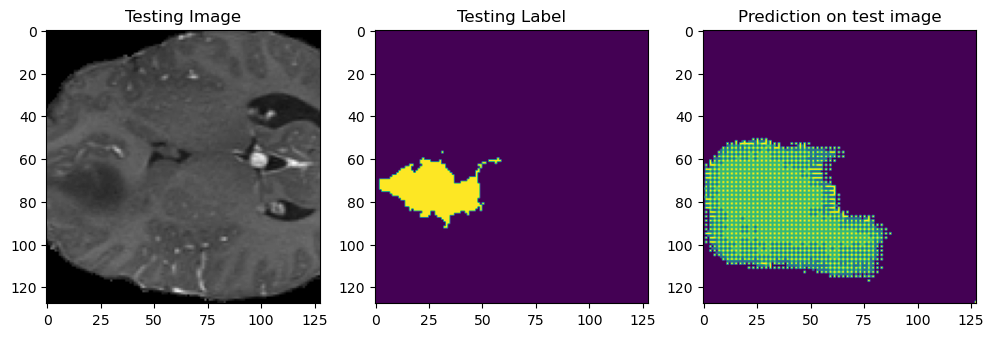

AUC = 0.5
Precesion = 0.9124955
Recall = 0.32018918
true positive = 762348.0
true negative = 14323180.0
false positive = 73106.0
false negative = 1618582.0
F1 score = 0.4740404436609884
pixel accuracy =  0.89916754
jaccard index =  0.31065072576253405
ARI(adjusted rand index) =  0.3791923335782803
tpr =  0.32018918
fpr =  0.0050781155


In [ ]:
from keras.metrics import MeanIoU

batch_size=8 #Check IoU for a batch of images
test_img_datagen = imageLoader(val_img_dir, val_img_list,
                                val_mask_dir, val_mask_list, batch_size)

#Verify generator.... In python 3 next() is renamed as __next__()
test_image_batch, test_mask_batch = test_img_datagen.__next__()

test_mask_batch_argmax = np.argmax(test_mask_batch, axis=4)
test_pred_batch = model.predict(test_image_batch)
test_pred_batch_argmax = np.argmax(test_pred_batch, axis=4)

n_classes = 4
IOU_keras = MeanIoU(num_classes=n_classes)
IOU_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Mean IoU =", IOU_keras.result().numpy())

img_num = 70

test_img = np.load("BraTS2020_TrainingData/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("BraTS2020_TrainingData/input_data_128/val/masks/mask_"+str(img_num)+".npy")
test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]

from matplotlib import pyplot as plt
import random

#n_slice=random.randint(0, test_prediction_argmax.shape[2])
n_slice = 55
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

from keras.metrics import AUC

AUC_keras=AUC(num_thresholds=2)
AUC_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("AUC =", AUC_keras.result().numpy())

pre = tf.keras.metrics.Precision()
pre.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Precesion =", pre.result().numpy())

recall = tf.keras.metrics.Recall()
recall.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Recall =", recall.result().numpy())

True_pos = tf.keras.metrics.TruePositives()
True_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true positive =", True_pos.result().numpy())

True_neg = tf.keras.metrics.TrueNegatives()
True_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true negative =", True_neg.result().numpy())

False_pos = tf.keras.metrics.FalsePositives()
False_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false positive =", False_pos.result().numpy())

False_neg = tf.keras.metrics.FalseNegatives()
False_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false negative =", False_neg.result().numpy())

F1_score=2*(pre.result().numpy()*recall.result().numpy())/(pre.result().numpy()+recall.result().numpy())
print("F1 score =", F1_score)

t_val = True_pos.result().numpy() + True_neg.result().numpy()
total = True_pos.result().numpy() + True_neg.result().numpy() +False_pos.result().numpy() + False_neg.result().numpy()

pixel_acc=t_val/total
print("pixel accuracy = ", pixel_acc)

jac = F1_score/(2-F1_score)
print("jaccard index = ", jac)

tp = True_pos.result().numpy()
tn = True_neg.result().numpy()
fp = False_pos.result().numpy()
fn = False_neg.result().numpy()

a = 0.5 * ( tp*(tp-1) + tn*(tn-1) + +fp*(fp-1) + fn*(fn-1) )
b = 0.5 * ( (tp+fn)*(tp+fn) + (tn+fp)*(tn+fp) - (tp*tp +tn*tn+fp*fp+fn*fn) )
c = 0.5 * ( (tp+fp)*(tp+fp) + (tn+fn)*(tn+fn) - (tp*tp +tn*tn+fp*fp+fn*fn) )
d = (total*(total-1)/2) - (a+b+c)
neu = 2 * ( a*d - b*c )
den = c*c + b*b + 2*a*d + (a+d)*(b+c)
ari = neu / den
print("ARI(adjusted rand index) = ", ari)

tpr=tp/(tp+fn)
fpr=fp/(fp+tn)
print("tpr = ", tpr)
print("fpr = ", fpr)

In [ ]:
# 2
history=model.fit(train_img_datagen,
          steps_per_epoch=steps_per_epoch,
          epochs=1,
          verbose=1,
          validation_data=val_img_datagen,
          validation_steps=val_steps_per_epoch

154/154 [==============================] - 7939s 51s/step - loss: -2.5913 - accuracy: 0.9402 - iou_score: 0.3314 - val_loss: -2.7378 - val_accuracy: 0.9445 - val_iou_score: 0.3338


1/1 [==============================] - 42s 42s/step
Mean IoU = 0.34341747
1/1 [==============================] - 6s 6s/step


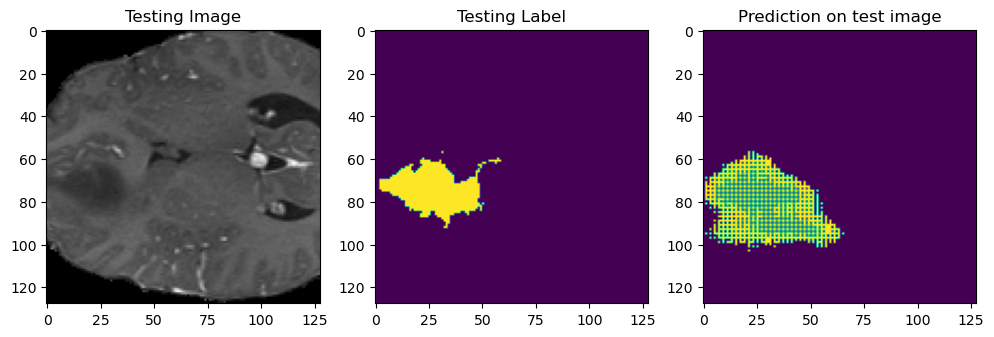

AUC = 0.5
Precesion = 0.7445317
Recall = 0.58889043
true positive = 622022.0
true negative = 15507523.0
false positive = 213432.0
false negative = 434239.0
F1 score = 0.657627568982713
pixel accuracy =  0.9613958
jaccard index =  0.4898994897297948
ARI(adjusted rand index) =  0.6099258386696031
tpr =  0.58889043
fpr =  0.013576275


In [ ]:
from keras.metrics import MeanIoU

batch_size=8 #Check IoU for a batch of images
test_img_datagen = imageLoader(val_img_dir, val_img_list,
                                val_mask_dir, val_mask_list, batch_size)

#Verify generator.... In python 3 next() is renamed as __next__()
test_image_batch, test_mask_batch = test_img_datagen.__next__()

test_mask_batch_argmax = np.argmax(test_mask_batch, axis=4)
test_pred_batch = model.predict(test_image_batch)
test_pred_batch_argmax = np.argmax(test_pred_batch, axis=4)

n_classes = 4
IOU_keras = MeanIoU(num_classes=n_classes)
IOU_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Mean IoU =", IOU_keras.result().numpy())

img_num = 70

test_img = np.load("BraTS2020_TrainingData/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("BraTS2020_TrainingData/input_data_128/val/masks/mask_"+str(img_num)+".npy")
test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]

from matplotlib import pyplot as plt
import random

#n_slice=random.randint(0, test_prediction_argmax.shape[2])
n_slice = 55
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

from keras.metrics import AUC

AUC_keras=AUC(num_thresholds=2)
AUC_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("AUC =", AUC_keras.result().numpy())

pre = tf.keras.metrics.Precision()
pre.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Precesion =", pre.result().numpy())

recall = tf.keras.metrics.Recall()
recall.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Recall =", recall.result().numpy())

True_pos = tf.keras.metrics.TruePositives()
True_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true positive =", True_pos.result().numpy())

True_neg = tf.keras.metrics.TrueNegatives()
True_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true negative =", True_neg.result().numpy())

False_pos = tf.keras.metrics.FalsePositives()
False_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false positive =", False_pos.result().numpy())

False_neg = tf.keras.metrics.FalseNegatives()
False_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false negative =", False_neg.result().numpy())

F1_score=2*(pre.result().numpy()*recall.result().numpy())/(pre.result().numpy()+recall.result().numpy())
print("F1 score =", F1_score)

t_val = True_pos.result().numpy() + True_neg.result().numpy()
total = True_pos.result().numpy() + True_neg.result().numpy() +False_pos.result().numpy() + False_neg.result().numpy()

pixel_acc=t_val/total
print("pixel accuracy = ", pixel_acc)

jac = F1_score/(2-F1_score)
print("jaccard index = ", jac)

tp = True_pos.result().numpy()
tn = True_neg.result().numpy()
fp = False_pos.result().numpy()
fn = False_neg.result().numpy()

a = 0.5 * ( tp*(tp-1) + tn*(tn-1) + +fp*(fp-1) + fn*(fn-1) )
b = 0.5 * ( (tp+fn)*(tp+fn) + (tn+fp)*(tn+fp) - (tp*tp +tn*tn+fp*fp+fn*fn) )
c = 0.5 * ( (tp+fp)*(tp+fp) + (tn+fn)*(tn+fn) - (tp*tp +tn*tn+fp*fp+fn*fn) )
d = (total*(total-1)/2) - (a+b+c)
neu = 2 * ( a*d - b*c )
den = c*c + b*b + 2*a*d + (a+d)*(b+c)
ari = neu / den
print("ARI(adjusted rand index) = ", ari)

tpr=tp/(tp+fn)
fpr=fp/(fp+tn)
print("tpr = ", tpr)
print("fpr = ", fpr)

In [ ]:
# 3
history=model.fit(train_img_datagen,
          steps_per_epoch=steps_per_epoch,
          epochs=1,
          verbose=1,
          validation_data=val_img_datagen,
          validation_steps=val_steps_per_epoch
          )

154/154 [==============================] - 7819s 51s/step - loss: -2.9729 - accuracy: 0.9393 - iou_score: 0.3410 - val_loss: -3.2273 - val_accuracy: 0.9546 - val_iou_score: 0.3493


1/1 [==============================] - 44s 44s/step
Mean IoU = 0.37231398
1/1 [==============================] - 5s 5s/step


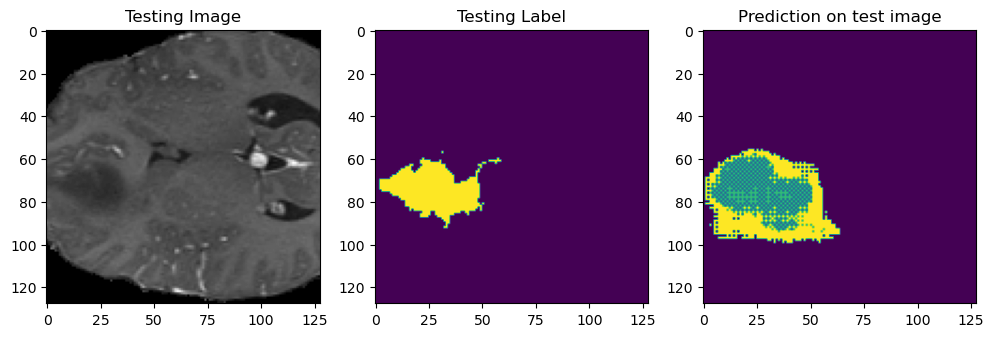

AUC = 0.5
Precesion = 0.7332349
Recall = 0.7048649
true positive = 612584.0
true negative = 15685266.0
false positive = 222870.0
false negative = 256496.0
F1 score = 0.7187699980834997
pixel accuracy =  0.97142756
jaccard index =  0.5609999742500122
ARI(adjusted rand index) =  0.6814725011183399
tpr =  0.7048649
fpr =  0.014009812


In [ ]:
from keras.metrics import MeanIoU

batch_size=8 #Check IoU for a batch of images
test_img_datagen = imageLoader(val_img_dir, val_img_list,
                                val_mask_dir, val_mask_list, batch_size)

#Verify generator.... In python 3 next() is renamed as __next__()
test_image_batch, test_mask_batch = test_img_datagen.__next__()

test_mask_batch_argmax = np.argmax(test_mask_batch, axis=4)
test_pred_batch = model.predict(test_image_batch)
test_pred_batch_argmax = np.argmax(test_pred_batch, axis=4)

n_classes = 4
IOU_keras = MeanIoU(num_classes=n_classes)
IOU_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Mean IoU =", IOU_keras.result().numpy())

img_num = 70

test_img = np.load("BraTS2020_TrainingData/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("BraTS2020_TrainingData/input_data_128/val/masks/mask_"+str(img_num)+".npy")
test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]

from matplotlib import pyplot as plt
import random

#n_slice=random.randint(0, test_prediction_argmax.shape[2])
n_slice = 55
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

from keras.metrics import AUC

AUC_keras=AUC(num_thresholds=2)
AUC_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("AUC =", AUC_keras.result().numpy())

pre = tf.keras.metrics.Precision()
pre.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Precesion =", pre.result().numpy())

recall = tf.keras.metrics.Recall()
recall.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Recall =", recall.result().numpy())

True_pos = tf.keras.metrics.TruePositives()
True_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true positive =", True_pos.result().numpy())

True_neg = tf.keras.metrics.TrueNegatives()
True_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true negative =", True_neg.result().numpy())

False_pos = tf.keras.metrics.FalsePositives()
False_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false positive =", False_pos.result().numpy())

False_neg = tf.keras.metrics.FalseNegatives()
False_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false negative =", False_neg.result().numpy())

F1_score=2*(pre.result().numpy()*recall.result().numpy())/(pre.result().numpy()+recall.result().numpy())
print("F1 score =", F1_score)

t_val = True_pos.result().numpy() + True_neg.result().numpy()
total = True_pos.result().numpy() + True_neg.result().numpy() +False_pos.result().numpy() + False_neg.result().numpy()

pixel_acc=t_val/total
print("pixel accuracy = ", pixel_acc)

jac = F1_score/(2-F1_score)
print("jaccard index = ", jac)

tp = True_pos.result().numpy()
tn = True_neg.result().numpy()
fp = False_pos.result().numpy()
fn = False_neg.result().numpy()

a = 0.5 * ( tp*(tp-1) + tn*(tn-1) + +fp*(fp-1) + fn*(fn-1) )
b = 0.5 * ( (tp+fn)*(tp+fn) + (tn+fp)*(tn+fp) - (tp*tp +tn*tn+fp*fp+fn*fn) )
c = 0.5 * ( (tp+fp)*(tp+fp) + (tn+fn)*(tn+fn) - (tp*tp +tn*tn+fp*fp+fn*fn) )
d = (total*(total-1)/2) - (a+b+c)
neu = 2 * ( a*d - b*c )
den = c*c + b*b + 2*a*d + (a+d)*(b+c)
ari = neu / den
print("ARI(adjusted rand index) = ", ari)

tpr=tp/(tp+fn)
fpr=fp/(fp+tn)
print("tpr = ", tpr)
print("fpr = ", fpr)

In [ ]:
#4
history=model.fit(train_img_datagen,
          steps_per_epoch=steps_per_epoch,
          epochs=1,
          verbose=1,
          validation_data=val_img_datagen,
          validation_steps=val_steps_per_epoch
          )

154/154 [==============================] - 7737s 50s/step - loss: -3.9864 - accuracy: 0.9553 - iou_score: 0.3734 - val_loss: -4.1071 - val_accuracy: 0.9500 - val_iou_score: 0.3728


1/1 [==============================] - 51s 51s/step
Mean IoU = 0.3631926
1/1 [==============================] - 9s 9s/step


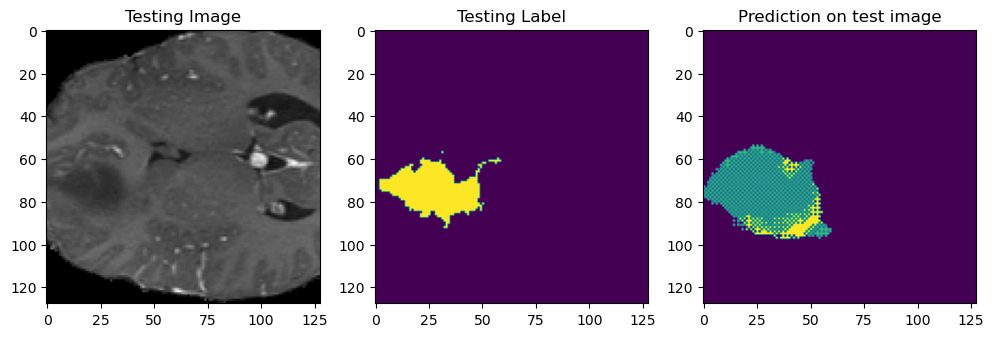

AUC = 0.5
Precesion = 0.86334854
Recall = 0.58616805
true positive = 721288.0
true negative = 15432536.0
false positive = 114166.0
false negative = 509226.0
F1 score = 0.6982567269211557
pixel accuracy =  0.96284294
jaccard index =  0.5364012561936731
ARI(adjusted rand index) =  0.6506845658482113
tpr =  0.58616805
fpr =  0.0073434226


In [ ]:
from keras.metrics import MeanIoU

batch_size=8 #Check IoU for a batch of images
test_img_datagen = imageLoader(val_img_dir, val_img_list,
                                val_mask_dir, val_mask_list, batch_size)

#Verify generator.... In python 3 next() is renamed as __next__()
test_image_batch, test_mask_batch = test_img_datagen.__next__()

test_mask_batch_argmax = np.argmax(test_mask_batch, axis=4)
test_pred_batch = model.predict(test_image_batch)
test_pred_batch_argmax = np.argmax(test_pred_batch, axis=4)

n_classes = 4
IOU_keras = MeanIoU(num_classes=n_classes)
IOU_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Mean IoU =", IOU_keras.result().numpy())

img_num = 70

test_img = np.load("BraTS2020_TrainingData/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("BraTS2020_TrainingData/input_data_128/val/masks/mask_"+str(img_num)+".npy")
test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]

from matplotlib import pyplot as plt
import random

#n_slice=random.randint(0, test_prediction_argmax.shape[2])
n_slice = 55
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

from keras.metrics import AUC

AUC_keras=AUC(num_thresholds=2)
AUC_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("AUC =", AUC_keras.result().numpy())

pre = tf.keras.metrics.Precision()
pre.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Precesion =", pre.result().numpy())

recall = tf.keras.metrics.Recall()
recall.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Recall =", recall.result().numpy())

True_pos = tf.keras.metrics.TruePositives()
True_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true positive =", True_pos.result().numpy())

True_neg = tf.keras.metrics.TrueNegatives()
True_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true negative =", True_neg.result().numpy())

False_pos = tf.keras.metrics.FalsePositives()
False_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false positive =", False_pos.result().numpy())

False_neg = tf.keras.metrics.FalseNegatives()
False_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false negative =", False_neg.result().numpy())

F1_score=2*(pre.result().numpy()*recall.result().numpy())/(pre.result().numpy()+recall.result().numpy())
print("F1 score =", F1_score)

t_val = True_pos.result().numpy() + True_neg.result().numpy()
total = True_pos.result().numpy() + True_neg.result().numpy() +False_pos.result().numpy() + False_neg.result().numpy()

pixel_acc=t_val/total
print("pixel accuracy = ", pixel_acc)

jac = F1_score/(2-F1_score)
print("jaccard index = ", jac)

tp = True_pos.result().numpy()
tn = True_neg.result().numpy()
fp = False_pos.result().numpy()
fn = False_neg.result().numpy()

a = 0.5 * ( tp*(tp-1) + tn*(tn-1) + +fp*(fp-1) + fn*(fn-1) )
b = 0.5 * ( (tp+fn)*(tp+fn) + (tn+fp)*(tn+fp) - (tp*tp +tn*tn+fp*fp+fn*fn) )
c = 0.5 * ( (tp+fp)*(tp+fp) + (tn+fn)*(tn+fn) - (tp*tp +tn*tn+fp*fp+fn*fn) )
d = (total*(total-1)/2) - (a+b+c)
neu = 2 * ( a*d - b*c )
den = c*c + b*b + 2*a*d + (a+d)*(b+c)
ari = neu / den
print("ARI(adjusted rand index) = ", ari)

tpr=tp/(tp+fn)
fpr=fp/(fp+tn)
print("tpr = ", tpr)
print("fpr = ", fpr)

In [ ]:
# 5
history=model.fit(train_img_datagen,
          steps_per_epoch=steps_per_epoch,
          epochs=1,
          verbose=1,
          validation_data=val_img_datagen,
          validation_steps=val_steps_per_epoch
          )

154/154 [==============================] - 7778s 50s/step - loss: -4.7589 - accuracy: 0.9596 - iou_score: 0.3977 - val_loss: -4.8736 - val_accuracy: 0.9545 - val_iou_score: 0.3965


1/1 [==============================] - 46s 46s/step
Mean IoU = 0.39291146
1/1 [==============================] - 8s 8s/step


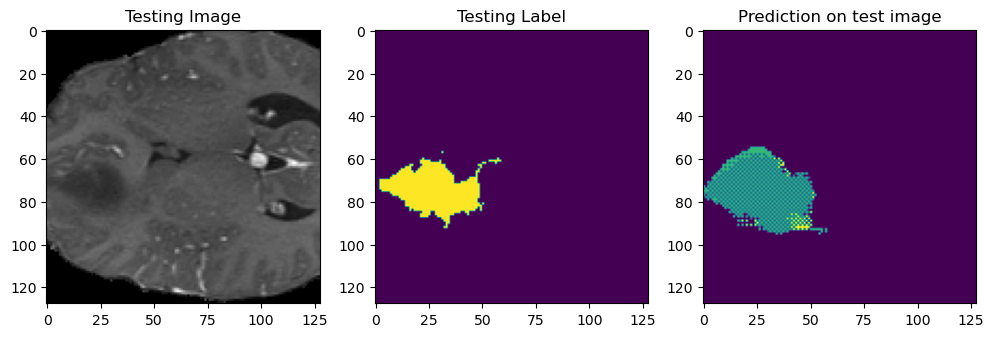

AUC = 0.5
Precesion = 0.89102334
Recall = 0.6052696
true positive = 744409.0
true negative = 15456291.0
false positive = 91045.0
false negative = 485471.0
F1 score = 0.7208606086052097
pixel accuracy =  0.96563697
jaccard index =  0.5635512544251913
ARI(adjusted rand index) =  0.6759316419889594
tpr =  0.6052696
fpr =  0.0058559873


In [ ]:
from keras.metrics import MeanIoU

batch_size=8 #Check IoU for a batch of images
test_img_datagen = imageLoader(val_img_dir, val_img_list,
                                val_mask_dir, val_mask_list, batch_size)

#Verify generator.... In python 3 next() is renamed as __next__()
test_image_batch, test_mask_batch = test_img_datagen.__next__()

test_mask_batch_argmax = np.argmax(test_mask_batch, axis=4)
test_pred_batch = model.predict(test_image_batch)
test_pred_batch_argmax = np.argmax(test_pred_batch, axis=4)

n_classes = 4
IOU_keras = MeanIoU(num_classes=n_classes)
IOU_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Mean IoU =", IOU_keras.result().numpy())

img_num = 70

test_img = np.load("BraTS2020_TrainingData/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("BraTS2020_TrainingData/input_data_128/val/masks/mask_"+str(img_num)+".npy")
test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]

from matplotlib import pyplot as plt
import random

#n_slice=random.randint(0, test_prediction_argmax.shape[2])
n_slice = 55
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

from keras.metrics import AUC

AUC_keras=AUC(num_thresholds=2)
AUC_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("AUC =", AUC_keras.result().numpy())

pre = tf.keras.metrics.Precision()
pre.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Precesion =", pre.result().numpy())

recall = tf.keras.metrics.Recall()
recall.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Recall =", recall.result().numpy())

True_pos = tf.keras.metrics.TruePositives()
True_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true positive =", True_pos.result().numpy())

True_neg = tf.keras.metrics.TrueNegatives()
True_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true negative =", True_neg.result().numpy())

False_pos = tf.keras.metrics.FalsePositives()
False_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false positive =", False_pos.result().numpy())

False_neg = tf.keras.metrics.FalseNegatives()
False_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false negative =", False_neg.result().numpy())

F1_score=2*(pre.result().numpy()*recall.result().numpy())/(pre.result().numpy()+recall.result().numpy())
print("F1 score =", F1_score)

t_val = True_pos.result().numpy() + True_neg.result().numpy()
total = True_pos.result().numpy() + True_neg.result().numpy() +False_pos.result().numpy() + False_neg.result().numpy()

pixel_acc=t_val/total
print("pixel accuracy = ", pixel_acc)

jac = F1_score/(2-F1_score)
print("jaccard index = ", jac)

tp = True_pos.result().numpy()
tn = True_neg.result().numpy()
fp = False_pos.result().numpy()
fn = False_neg.result().numpy()

a = 0.5 * ( tp*(tp-1) + tn*(tn-1) + +fp*(fp-1) + fn*(fn-1) )
b = 0.5 * ( (tp+fn)*(tp+fn) + (tn+fp)*(tn+fp) - (tp*tp +tn*tn+fp*fp+fn*fn) )
c = 0.5 * ( (tp+fp)*(tp+fp) + (tn+fn)*(tn+fn) - (tp*tp +tn*tn+fp*fp+fn*fn) )
d = (total*(total-1)/2) - (a+b+c)
neu = 2 * ( a*d - b*c )
den = c*c + b*b + 2*a*d + (a+d)*(b+c)
ari = neu / den
print("ARI(adjusted rand index) = ", ari)

tpr=tp/(tp+fn)
fpr=fp/(fp+tn)
print("tpr = ", tpr)
print("fpr = ", fpr)

In [ ]:
# 6
history=model.fit(train_img_datagen,
          steps_per_epoch=steps_per_epoch,
          epochs=1,
          verbose=1,
          validation_data=val_img_datagen,
          validation_steps=val_steps_per_epoch
          )

154/154 [==============================] - 7959s 52s/step - loss: -5.3675 - accuracy: 0.9618 - iou_score: 0.4175 - val_loss: -5.4751 - val_accuracy: 0.9556 - val_iou_score: 0.4145


1/1 [==============================] - 46s 46s/step
Mean IoU = 0.41354093
1/1 [==============================] - 6s 6s/step


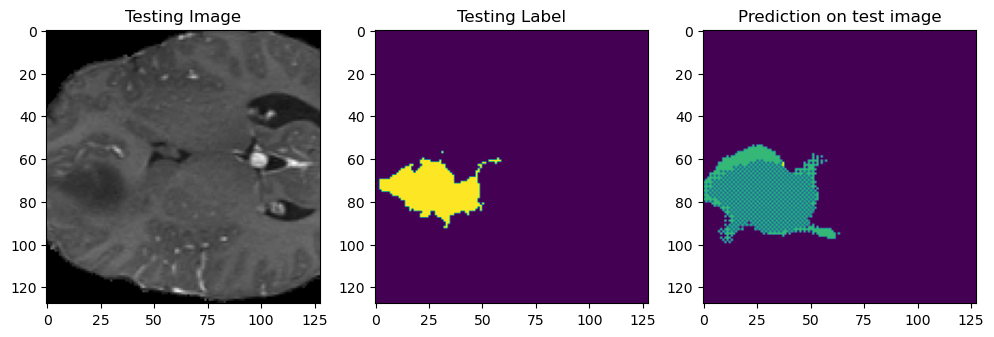

AUC = 0.5
Precesion = 0.94092554
Recall = 0.62145144
true positive = 786100.0
true negative = 15462920.0
false positive = 49354.0
false negative = 478842.0
F1 score = 0.7485255034118287
pixel accuracy =  0.96851707
jaccard index =  0.5981148680636273
ARI(adjusted rand index) =  0.7063439390592511
tpr =  0.62145144
fpr =  0.0031816096


In [ ]:
from keras.metrics import MeanIoU

batch_size=8 #Check IoU for a batch of images
test_img_datagen = imageLoader(val_img_dir, val_img_list,
                                val_mask_dir, val_mask_list, batch_size)

#Verify generator.... In python 3 next() is renamed as __next__()
test_image_batch, test_mask_batch = test_img_datagen.__next__()

test_mask_batch_argmax = np.argmax(test_mask_batch, axis=4)
test_pred_batch = model.predict(test_image_batch)
test_pred_batch_argmax = np.argmax(test_pred_batch, axis=4)

n_classes = 4
IOU_keras = MeanIoU(num_classes=n_classes)
IOU_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Mean IoU =", IOU_keras.result().numpy())

img_num = 70

test_img = np.load("BraTS2020_TrainingData/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("BraTS2020_TrainingData/input_data_128/val/masks/mask_"+str(img_num)+".npy")
test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]

from matplotlib import pyplot as plt
import random

#n_slice=random.randint(0, test_prediction_argmax.shape[2])
n_slice = 55
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

from keras.metrics import AUC

AUC_keras=AUC(num_thresholds=2)
AUC_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("AUC =", AUC_keras.result().numpy())

pre = tf.keras.metrics.Precision()
pre.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Precesion =", pre.result().numpy())

recall = tf.keras.metrics.Recall()
recall.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Recall =", recall.result().numpy())

True_pos = tf.keras.metrics.TruePositives()
True_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true positive =", True_pos.result().numpy())

True_neg = tf.keras.metrics.TrueNegatives()
True_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true negative =", True_neg.result().numpy())

False_pos = tf.keras.metrics.FalsePositives()
False_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false positive =", False_pos.result().numpy())

False_neg = tf.keras.metrics.FalseNegatives()
False_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false negative =", False_neg.result().numpy())

F1_score=2*(pre.result().numpy()*recall.result().numpy())/(pre.result().numpy()+recall.result().numpy())
print("F1 score =", F1_score)

t_val = True_pos.result().numpy() + True_neg.result().numpy()
total = True_pos.result().numpy() + True_neg.result().numpy() +False_pos.result().numpy() + False_neg.result().numpy()

pixel_acc=t_val/total
print("pixel accuracy = ", pixel_acc)

jac = F1_score/(2-F1_score)
print("jaccard index = ", jac)

tp = True_pos.result().numpy()
tn = True_neg.result().numpy()
fp = False_pos.result().numpy()
fn = False_neg.result().numpy()

a = 0.5 * ( tp*(tp-1) + tn*(tn-1) + +fp*(fp-1) + fn*(fn-1) )
b = 0.5 * ( (tp+fn)*(tp+fn) + (tn+fp)*(tn+fp) - (tp*tp +tn*tn+fp*fp+fn*fn) )
c = 0.5 * ( (tp+fp)*(tp+fp) + (tn+fn)*(tn+fn) - (tp*tp +tn*tn+fp*fp+fn*fn) )
d = (total*(total-1)/2) - (a+b+c)
neu = 2 * ( a*d - b*c )
den = c*c + b*b + 2*a*d + (a+d)*(b+c)
ari = neu / den
print("ARI(adjusted rand index) = ", ari)

tpr=tp/(tp+fn)
fpr=fp/(fp+tn)
print("tpr = ", tpr)
print("fpr = ", fpr)

In [ ]:
# 7
history=model.fit(train_img_datagen,
          steps_per_epoch=steps_per_epoch,
          epochs=1,
          verbose=1,
          validation_data=val_img_datagen,
          validation_steps=val_steps_per_epoch
          )

154/154 [==============================] - 7742s 50s/step - loss: -6.0910 - accuracy: 0.9661 - iou_score: 0.4424 - val_loss: -5.7277 - val_accuracy: 0.9472 - val_iou_score: 0.4218


1/1 [==============================] - 40s 40s/step
Mean IoU = 0.4112388
1/1 [==============================] - 5s 5s/step


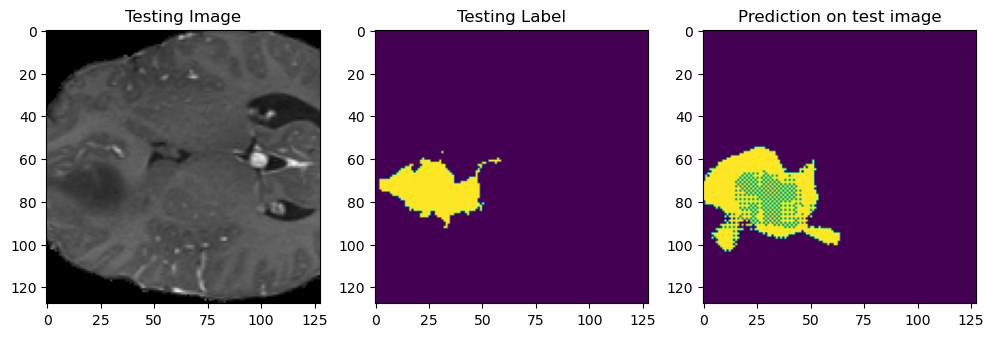

AUC = 0.5
Precesion = 0.96175253
Recall = 0.5284415
true positive = 803500.0
true negative = 15224753.0
false positive = 31954.0
false negative = 717009.0
F1 score = 0.6820989525828008
pixel accuracy =  0.9553583
jaccard index =  0.5175646183145292
ARI(adjusted rand index) =  0.6263276404508048
tpr =  0.5284415
fpr =  0.0020944232


In [ ]:
from keras.metrics import MeanIoU

batch_size=8 #Check IoU for a batch of images
test_img_datagen = imageLoader(val_img_dir, val_img_list,
                                val_mask_dir, val_mask_list, batch_size)

#Verify generator.... In python 3 next() is renamed as __next__()
test_image_batch, test_mask_batch = test_img_datagen.__next__()

test_mask_batch_argmax = np.argmax(test_mask_batch, axis=4)
test_pred_batch = model.predict(test_image_batch)
test_pred_batch_argmax = np.argmax(test_pred_batch, axis=4)

n_classes = 4
IOU_keras = MeanIoU(num_classes=n_classes)
IOU_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Mean IoU =", IOU_keras.result().numpy())

img_num = 70

test_img = np.load("BraTS2020_TrainingData/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("BraTS2020_TrainingData/input_data_128/val/masks/mask_"+str(img_num)+".npy")
test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]

from matplotlib import pyplot as plt
import random

#n_slice=random.randint(0, test_prediction_argmax.shape[2])
n_slice = 55
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

from keras.metrics import AUC

AUC_keras=AUC(num_thresholds=2)
AUC_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("AUC =", AUC_keras.result().numpy())

pre = tf.keras.metrics.Precision()
pre.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Precesion =", pre.result().numpy())

recall = tf.keras.metrics.Recall()
recall.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Recall =", recall.result().numpy())

True_pos = tf.keras.metrics.TruePositives()
True_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true positive =", True_pos.result().numpy())

True_neg = tf.keras.metrics.TrueNegatives()
True_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true negative =", True_neg.result().numpy())

False_pos = tf.keras.metrics.FalsePositives()
False_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false positive =", False_pos.result().numpy())

False_neg = tf.keras.metrics.FalseNegatives()
False_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false negative =", False_neg.result().numpy())

F1_score=2*(pre.result().numpy()*recall.result().numpy())/(pre.result().numpy()+recall.result().numpy())
print("F1 score =", F1_score)

t_val = True_pos.result().numpy() + True_neg.result().numpy()
total = True_pos.result().numpy() + True_neg.result().numpy() +False_pos.result().numpy() + False_neg.result().numpy()

pixel_acc=t_val/total
print("pixel accuracy = ", pixel_acc)

jac = F1_score/(2-F1_score)
print("jaccard index = ", jac)

tp = True_pos.result().numpy()
tn = True_neg.result().numpy()
fp = False_pos.result().numpy()
fn = False_neg.result().numpy()

a = 0.5 * ( tp*(tp-1) + tn*(tn-1) + +fp*(fp-1) + fn*(fn-1) )
b = 0.5 * ( (tp+fn)*(tp+fn) + (tn+fp)*(tn+fp) - (tp*tp +tn*tn+fp*fp+fn*fn) )
c = 0.5 * ( (tp+fp)*(tp+fp) + (tn+fn)*(tn+fn) - (tp*tp +tn*tn+fp*fp+fn*fn) )
d = (total*(total-1)/2) - (a+b+c)
neu = 2 * ( a*d - b*c )
den = c*c + b*b + 2*a*d + (a+d)*(b+c)
ari = neu / den
print("ARI(adjusted rand index) = ", ari)

tpr=tp/(tp+fn)
fpr=fp/(fp+tn)
print("tpr = ", tpr)
print("fpr = ", fpr)

In [ ]:
# 8
history=model.fit(train_img_datagen,
          steps_per_epoch=steps_per_epoch,
          epochs=1,
          verbose=1,
          validation_data=val_img_datagen,
          validation_steps=val_steps_per_epoch
          )

154/154 [==============================] - 7822s 51s/step - loss: -6.6852 - accuracy: 0.9682 - iou_score: 0.4651 - val_loss: -6.5969 - val_accuracy: 0.9580 - val_iou_score: 0.4549


1/1 [==============================] - 56s 56s/step
Mean IoU = 0.4513163
1/1 [==============================] - 5s 5s/step


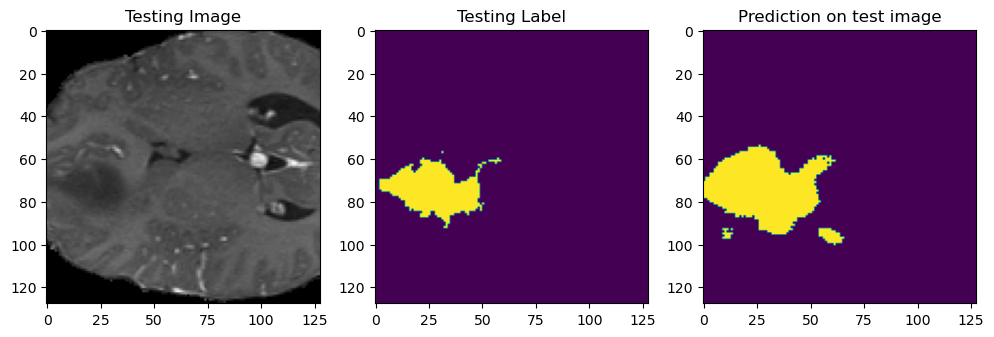

AUC = 0.5
Precesion = 0.91973585
Recall = 0.5705159
true positive = 768397.0
true negative = 15363313.0
false positive = 67057.0
false negative = 578449.0
F1 score = 0.7042083688700981
pixel accuracy =  0.96152484
jaccard index =  0.5434580313318151
ARI(adjusted rand index) =  0.6548240519166725
tpr =  0.5705159
fpr =  0.0043457802


In [ ]:
from keras.metrics import MeanIoU

batch_size=8 #Check IoU for a batch of images
test_img_datagen = imageLoader(val_img_dir, val_img_list,
                                val_mask_dir, val_mask_list, batch_size)

#Verify generator.... In python 3 next() is renamed as __next__()
test_image_batch, test_mask_batch = test_img_datagen.__next__()

test_mask_batch_argmax = np.argmax(test_mask_batch, axis=4)
test_pred_batch = model.predict(test_image_batch)
test_pred_batch_argmax = np.argmax(test_pred_batch, axis=4)

n_classes = 4
IOU_keras = MeanIoU(num_classes=n_classes)
IOU_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Mean IoU =", IOU_keras.result().numpy())

img_num = 70

test_img = np.load("BraTS2020_TrainingData/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("BraTS2020_TrainingData/input_data_128/val/masks/mask_"+str(img_num)+".npy")
test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]

from matplotlib import pyplot as plt
import random

#n_slice=random.randint(0, test_prediction_argmax.shape[2])
n_slice = 55
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

from keras.metrics import AUC

AUC_keras=AUC(num_thresholds=2)
AUC_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("AUC =", AUC_keras.result().numpy())

pre = tf.keras.metrics.Precision()
pre.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Precesion =", pre.result().numpy())

recall = tf.keras.metrics.Recall()
recall.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Recall =", recall.result().numpy())

True_pos = tf.keras.metrics.TruePositives()
True_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true positive =", True_pos.result().numpy())

True_neg = tf.keras.metrics.TrueNegatives()
True_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true negative =", True_neg.result().numpy())

False_pos = tf.keras.metrics.FalsePositives()
False_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false positive =", False_pos.result().numpy())

False_neg = tf.keras.metrics.FalseNegatives()
False_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false negative =", False_neg.result().numpy())

F1_score=2*(pre.result().numpy()*recall.result().numpy())/(pre.result().numpy()+recall.result().numpy())
print("F1 score =", F1_score)

t_val = True_pos.result().numpy() + True_neg.result().numpy()
total = True_pos.result().numpy() + True_neg.result().numpy() +False_pos.result().numpy() + False_neg.result().numpy()

pixel_acc=t_val/total
print("pixel accuracy = ", pixel_acc)

jac = F1_score/(2-F1_score)
print("jaccard index = ", jac)

tp = True_pos.result().numpy()
tn = True_neg.result().numpy()
fp = False_pos.result().numpy()
fn = False_neg.result().numpy()

a = 0.5 * ( tp*(tp-1) + tn*(tn-1) + +fp*(fp-1) + fn*(fn-1) )
b = 0.5 * ( (tp+fn)*(tp+fn) + (tn+fp)*(tn+fp) - (tp*tp +tn*tn+fp*fp+fn*fn) )
c = 0.5 * ( (tp+fp)*(tp+fp) + (tn+fn)*(tn+fn) - (tp*tp +tn*tn+fp*fp+fn*fn) )
d = (total*(total-1)/2) - (a+b+c)
neu = 2 * ( a*d - b*c )
den = c*c + b*b + 2*a*d + (a+d)*(b+c)
ari = neu / den
print("ARI(adjusted rand index) = ", ari)

tpr=tp/(tp+fn)
fpr=fp/(fp+tn)
print("tpr = ", tpr)
print("fpr = ", fpr)

In [ ]:
# 9
history=model.fit(train_img_datagen,
          steps_per_epoch=steps_per_epoch,
          epochs=1,
          verbose=1,
          validation_data=val_img_datagen,
          validation_steps=val_steps_per_epoch
          )

154/154 [==============================] - 7937s 51s/step - loss: -7.2046 - accuracy: 0.9698 - iou_score: 0.4832 - val_loss: -7.4189 - val_accuracy: 0.9603 - val_iou_score: 0.4830


1/1 [==============================] - 48s 48s/step
Mean IoU = 0.49136966
1/1 [==============================] - 5s 5s/step


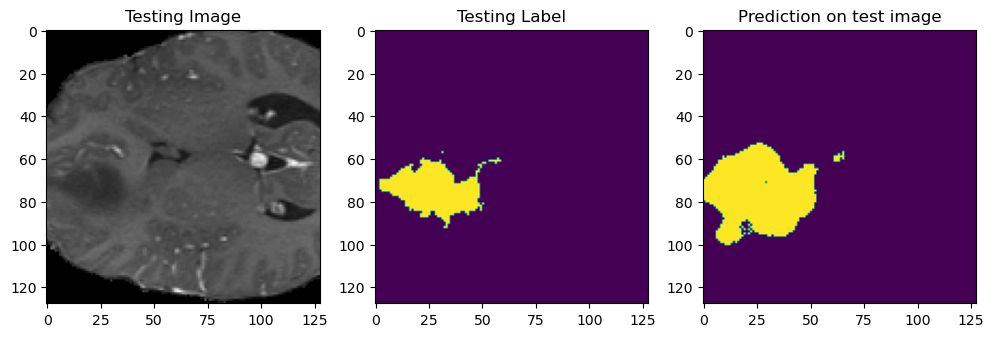

AUC = 0.5
Precesion = 0.9464363
Recall = 0.64217687
true positive = 790704.0
true negative = 15501179.0
false positive = 44750.0
false negative = 440583.0
F1 score = 0.7651699243590828
pixel accuracy =  0.9710719
jaccard index =  0.6196560477861172
ARI(adjusted rand index) =  0.7258056062147864
tpr =  0.64217687
fpr =  0.0028785672


In [ ]:
from keras.metrics import MeanIoU

batch_size=8 #Check IoU for a batch of images
test_img_datagen = imageLoader(val_img_dir, val_img_list,
                                val_mask_dir, val_mask_list, batch_size)

#Verify generator.... In python 3 next() is renamed as __next__()
test_image_batch, test_mask_batch = test_img_datagen.__next__()

test_mask_batch_argmax = np.argmax(test_mask_batch, axis=4)
test_pred_batch = model.predict(test_image_batch)
test_pred_batch_argmax = np.argmax(test_pred_batch, axis=4)

n_classes = 4
IOU_keras = MeanIoU(num_classes=n_classes)
IOU_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Mean IoU =", IOU_keras.result().numpy())

img_num = 70

test_img = np.load("BraTS2020_TrainingData/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("BraTS2020_TrainingData/input_data_128/val/masks/mask_"+str(img_num)+".npy")
test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]

from matplotlib import pyplot as plt
import random

#n_slice=random.randint(0, test_prediction_argmax.shape[2])
n_slice = 55
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

from keras.metrics import AUC

AUC_keras=AUC(num_thresholds=2)
AUC_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("AUC =", AUC_keras.result().numpy())

pre = tf.keras.metrics.Precision()
pre.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Precesion =", pre.result().numpy())

recall = tf.keras.metrics.Recall()
recall.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Recall =", recall.result().numpy())

True_pos = tf.keras.metrics.TruePositives()
True_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true positive =", True_pos.result().numpy())

True_neg = tf.keras.metrics.TrueNegatives()
True_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true negative =", True_neg.result().numpy())

False_pos = tf.keras.metrics.FalsePositives()
False_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false positive =", False_pos.result().numpy())

False_neg = tf.keras.metrics.FalseNegatives()
False_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false negative =", False_neg.result().numpy())

F1_score=2*(pre.result().numpy()*recall.result().numpy())/(pre.result().numpy()+recall.result().numpy())
print("F1 score =", F1_score)

t_val = True_pos.result().numpy() + True_neg.result().numpy()
total = True_pos.result().numpy() + True_neg.result().numpy() +False_pos.result().numpy() + False_neg.result().numpy()

pixel_acc=t_val/total
print("pixel accuracy = ", pixel_acc)

jac = F1_score/(2-F1_score)
print("jaccard index = ", jac)

tp = True_pos.result().numpy()
tn = True_neg.result().numpy()
fp = False_pos.result().numpy()
fn = False_neg.result().numpy()

a = 0.5 * ( tp*(tp-1) + tn*(tn-1) + +fp*(fp-1) + fn*(fn-1) )
b = 0.5 * ( (tp+fn)*(tp+fn) + (tn+fp)*(tn+fp) - (tp*tp +tn*tn+fp*fp+fn*fn) )
c = 0.5 * ( (tp+fp)*(tp+fp) + (tn+fn)*(tn+fn) - (tp*tp +tn*tn+fp*fp+fn*fn) )
d = (total*(total-1)/2) - (a+b+c)
neu = 2 * ( a*d - b*c )
den = c*c + b*b + 2*a*d + (a+d)*(b+c)
ari = neu / den
print("ARI(adjusted rand index) = ", ari)

tpr=tp/(tp+fn)
fpr=fp/(fp+tn)
print("tpr = ", tpr)
print("fpr = ", fpr)

In [ ]:
# 10
history=model.fit(train_img_datagen,
          steps_per_epoch=steps_per_epoch,
          epochs=1,
          verbose=1,
          validation_data=val_img_datagen,
          validation_steps=val_steps_per_epoch
          )

154/154 [==============================] - 8843s 57s/step - loss: -7.6924 - accuracy: 0.9712 - iou_score: 0.5020 - val_loss: -7.8940 - val_accuracy: 0.9661 - val_iou_score: 0.5018


1/1 [==============================] - 81s 81s/step
Mean IoU = 0.53379214
1/1 [==============================] - 10s 10s/step


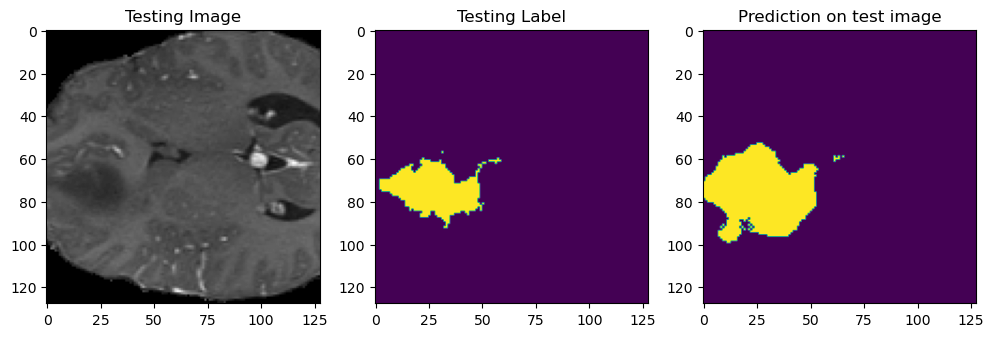

AUC = 0.5
Precesion = 0.9436043
Recall = 0.7142684
true positive = 788338.0
true negative = 15626400.0
false positive = 47116.0
false negative = 315362.0
F1 score = 0.8130741791831653
pixel accuracy =  0.9783946
jaccard index =  0.6850252685745878
ARI(adjusted rand index) =  0.7823970256503872
tpr =  0.7142684
fpr =  0.00300609


In [ ]:
from keras.metrics import MeanIoU

batch_size=8 #Check IoU for a batch of images
test_img_datagen = imageLoader(val_img_dir, val_img_list,
                                val_mask_dir, val_mask_list, batch_size)

#Verify generator.... In python 3 next() is renamed as __next__()
test_image_batch, test_mask_batch = test_img_datagen.__next__()

test_mask_batch_argmax = np.argmax(test_mask_batch, axis=4)
test_pred_batch = model.predict(test_image_batch)
test_pred_batch_argmax = np.argmax(test_pred_batch, axis=4)

n_classes = 4
IOU_keras = MeanIoU(num_classes=n_classes)
IOU_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Mean IoU =", IOU_keras.result().numpy())

img_num = 70

test_img = np.load("BraTS2020_TrainingData/input_data_128/val/images/image_"+str(img_num)+".npy")

test_mask = np.load("BraTS2020_TrainingData/input_data_128/val/masks/mask_"+str(img_num)+".npy")
test_mask_argmax=np.argmax(test_mask, axis=3)

test_img_input = np.expand_dims(test_img, axis=0)
test_prediction = model.predict(test_img_input)
test_prediction_argmax=np.argmax(test_prediction, axis=4)[0,:,:,:]

from matplotlib import pyplot as plt
import random

#n_slice=random.randint(0, test_prediction_argmax.shape[2])
n_slice = 55
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(test_img[:,:,n_slice,1], cmap='gray')
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(test_mask_argmax[:,:,n_slice])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(test_prediction_argmax[:,:, n_slice])
plt.show()

from keras.metrics import AUC

AUC_keras=AUC(num_thresholds=2)
AUC_keras.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("AUC =", AUC_keras.result().numpy())

pre = tf.keras.metrics.Precision()
pre.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Precesion =", pre.result().numpy())

recall = tf.keras.metrics.Recall()
recall.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("Recall =", recall.result().numpy())

True_pos = tf.keras.metrics.TruePositives()
True_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true positive =", True_pos.result().numpy())

True_neg = tf.keras.metrics.TrueNegatives()
True_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("true negative =", True_neg.result().numpy())

False_pos = tf.keras.metrics.FalsePositives()
False_pos.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false positive =", False_pos.result().numpy())

False_neg = tf.keras.metrics.FalseNegatives()
False_neg.update_state(test_pred_batch_argmax, test_mask_batch_argmax)
print("false negative =", False_neg.result().numpy())

F1_score=2*(pre.result().numpy()*recall.result().numpy())/(pre.result().numpy()+recall.result().numpy())
print("F1 score =", F1_score)

t_val = True_pos.result().numpy() + True_neg.result().numpy()
total = True_pos.result().numpy() + True_neg.result().numpy() +False_pos.result().numpy() + False_neg.result().numpy()

pixel_acc=t_val/total
print("pixel accuracy = ", pixel_acc)

jac = F1_score/(2-F1_score)
print("jaccard index = ", jac)

tp = True_pos.result().numpy()
tn = True_neg.result().numpy()
fp = False_pos.result().numpy()
fn = False_neg.result().numpy()

a = 0.5 * ( tp*(tp-1) + tn*(tn-1) + +fp*(fp-1) + fn*(fn-1) )
b = 0.5 * ( (tp+fn)*(tp+fn) + (tn+fp)*(tn+fp) - (tp*tp +tn*tn+fp*fp+fn*fn) )
c = 0.5 * ( (tp+fp)*(tp+fp) + (tn+fn)*(tn+fn) - (tp*tp +tn*tn+fp*fp+fn*fn) )
d = (total*(total-1)/2) - (a+b+c)
neu = 2 * ( a*d - b*c )
den = c*c + b*b + 2*a*d + (a+d)*(b+c)
ari = neu / den
print("ARI(adjusted rand index) = ", ari)

tpr=tp/(tp+fn)
fpr=fp/(fp+tn)
print("tpr = ", tpr)
print("fpr = ", fpr)

In [ ]:
spec = tn/(tn+fp)
print(f"Spec = {spec}")

ppv = tp/(tp+fp)
print(f"Ppv = {ppv}")

npv = tn/(tn+fn)
print(f"Npv = {npv}")

Spec = 0.996993899345398
Ppv = 0.9436042904853821
Npv = 0.9802178740501404


In [ ]:
from sklearn import metrics

y_true = []
y_pred = []

test_img_dir="./BraTS2020_TrainingData/input_data_128/val/images"
test_seg_dir="./BraTS2020_TrainingData/input_data_128/val/masks"
for img in os.listdir(test_img_dir):

#     print(img)
    num=img.split(".")[0].split("_")[-1]
#     print(num)
    test_img = np.load("./BraTS2020_TrainingData/input_data_128/val/images/"+str(img)+"").astype('float32',casting = 'same_kind')

    test_mask = np.load("./BraTS2020_TrainingData/input_data_128/val/masks/mask_"+str(num)+".npy").astype('float32',casting = 'same_kind')

    test_mask_argmax=np.argmax( test_mask, axis=0)

    test_img_input = np.expand_dims(test_img, axis=0)
    pred = model.predict(test_img_input)
# #         pred = model(img)  # get prediction for each pixel in the image
    y_true.append(test_mask.flatten())  # flatten all targets
    y_pred.append(pred.flatten())  # flatten all predictions

# concatenate all predictions and targets:
y_true = np.concatenate(y_true, axis=0)
y_pred = np.concatenate(y_pred, axis=0)
# copte the ROC curve
frp, trp, thresholds = metrics.roc_curve(y_true, y_pred)

C:\ProgramData\Anaconda3\envs\Tensorflow\lib\site-packages\tensorflow\python\data\ops\structured_function.py:264: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1/1 [==============================] - 9s 9s/step


MemoryError: 

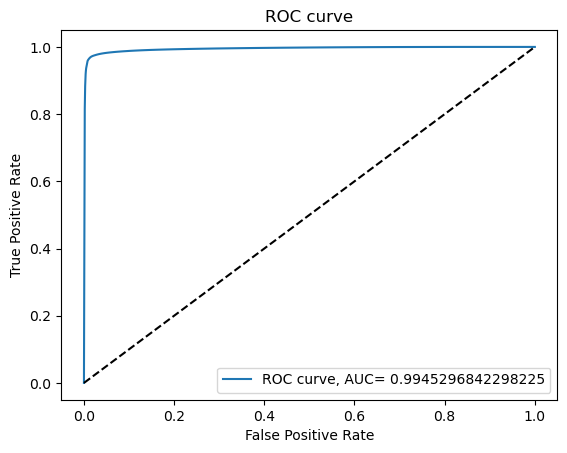

In [ ]:
import sklearn
from sklearn.metrics import roc_curve, auc

roc_auc = auc(frp,trp)
plt.plot(frp,trp,label="ROC curve, AUC= "+str(roc_auc))
plt.plot([0,1], [0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve")
plt.legend()
plt.show()